# Model 1 v2 – 03 Data Preparation
**Purpose:** Rebuild the X-ray vs non-X-ray dataset with (1) more X-ray variety (Model 2 limb X-rays + chest) and
(2) hard negatives (OCT, skin, microscopy, everyday objects), keeping the v1 unseen-source test sources unseen.
**Inputs:** outputs/manifest_split.csv (v1), outputs/model2/manifest_split.csv, NON_XRAY_extra/ (downloaded here)
**Outputs:** outputs/model1_v2/ (inventory, manifest_split_v2.csv, cache_224_v2.npz)
**Note:** v1 files are not changed (kept for the v1-vs-v2 comparison).

In [1]:
# ===== SETTINGS =====
from pathlib import Path

DRIVE_ROOT  = Path('/content/drive/MyDrive/Research')
V1_MANIFEST = DRIVE_ROOT / 'outputs' / 'manifest_split.csv'
M2_MANIFEST = DRIVE_ROOT / 'outputs' / 'model2' / 'manifest_split.csv'
NEG_DIR     = DRIVE_ROOT / 'NON_XRAY_extra'          # new hard negatives are saved here
OUT_DIR     = DRIVE_ROOT / 'outputs' / 'model1_v2'

SEED = 42
N_PER_MEDMNIST = 300      # images per new MedMNIST negative source
N_OBJECTS      = 600      # everyday-object photos (Imagenette)

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd
from PIL import Image
OUT_DIR.mkdir(parents=True, exist_ok=True); NEG_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)
print('v1 manifest exists:', V1_MANIFEST.exists(), '| Model 2 manifest exists:', M2_MANIFEST.exists())

Mounted at /content/drive
v1 manifest exists: True | Model 2 manifest exists: True


## Step 1 – Download hard negatives (not X-rays, but some look similar)
OCTMNIST = retinal OCT scans (grayscale, X-ray-like) · DermaMNIST = skin photos · BloodMNIST = blood microscopy ·
Imagenette = everyday objects (bottle-like photos). None of these sources is used in the unseen test.

In [3]:
!pip install -q medmnist
from medmnist import OCTMNIST, DermaMNIST, BloodMNIST

for Cls, name, size in [(OCTMNIST, 'OCT_OCTMNIST', 128),
                        (DermaMNIST, 'Skin_DermaMNIST', 128),
                        (BloodMNIST, 'Microscopy_BloodMNIST', 64)]:
    folder = NEG_DIR / name
    if folder.exists() and len(list(folder.glob('*.png'))) >= N_PER_MEDMNIST:
        print('Already saved:', name); continue
    folder.mkdir(parents=True, exist_ok=True)
    ds = Cls(split='train', download=True, size=size, root='/content')
    for i in rng.choice(len(ds.imgs), N_PER_MEDMNIST, replace=False):
        Image.fromarray(ds.imgs[i]).save(folder / f'{name}_{i:06d}.png')
    print('Saved', N_PER_MEDMNIST, 'images ->', folder)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 10.7 MB/s eta 0:00:00
Already saved: OCT_OCTMNIST
Already saved: Skin_DermaMNIST
Already saved: Microscopy_BloodMNIST


In [4]:
import shutil
folder = NEG_DIR / 'Objects_Imagenette'
if folder.exists() and len(list(folder.glob('*'))) >= N_OBJECTS:
    print('Already saved: Objects_Imagenette')
else:
    !wget -q https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz -O /content/imagenette.tgz
    !tar -xzf /content/imagenette.tgz -C /content
    files = sorted(Path('/content/imagenette2-160/train').rglob('*.JPEG'))
    folder.mkdir(parents=True, exist_ok=True)
    for i in rng.choice(len(files), N_OBJECTS, replace=False):
        shutil.copy(files[i], folder / f'obj_{files[i].name}')
    print('Saved', N_OBJECTS, 'object photos ->', folder)

Already saved: Objects_Imagenette


## Step 2 – Inventory of all sources
X_RAY: v1 X-rays (v1 split) + Model 2 limb/chest X-rays (Model 2 split, so pipeline test images stay test).
NON_XRAY: v1 non-X-rays (v1 split) + new hard negatives (split assigned in Step 4).

In [5]:
v1 = pd.read_csv(V1_MANIFEST)
print('v1 manifest columns:', list(v1.columns))
v1 = v1[v1.split != 'not_used']
v1 = pd.DataFrame({'path': v1.path, 'label': v1.label, 'source': 'v1_' + v1.source,
                   'group': 'v1_' + v1['group_id'].astype(str), 'split': v1.split})

m2 = pd.read_csv(M2_MANIFEST)
m2 = pd.DataFrame({'path': m2.path, 'label': 'X_RAY',
                   'source': 'm2_' + m2.label.str.split(' - ').str[0].str.replace(' ', '_'),
                   'group': 'm2_' + m2.dup_group.astype(str), 'split': m2.split})

neg = pd.DataFrame([{'path': str(p), 'label': 'NON_XRAY', 'source': 'new_' + d.name,
                     'group': 'new_' + p.stem, 'split': 'unassigned'}
                    for d in sorted(NEG_DIR.iterdir()) if d.is_dir() for p in sorted(d.glob('*')) if p.is_file()])

inv = pd.concat([v1, m2, neg], ignore_index=True)
print('\nTotal images:', len(inv))
print(inv.groupby(['label', 'source']).size().to_string())
print('\nPer label:', inv.label.value_counts().to_dict())
inv.to_csv(OUT_DIR / 'inventory_v2.csv', index=False)

v1 manifest columns: ['path', 'filename', 'label', 'source', 'group_id', 'md5', 'width', 'height', 'mode', 'readable', 'is_duplicate', 'split']

Total images: 8685
label     source                   
NON_XRAY  new_Microscopy_BloodMNIST     300
          new_OCT_OCTMNIST              300
          new_Objects_Imagenette        600
          new_Skin_DermaMNIST           300
          v1_animals_512_unknown        320
          v1_brain_mri_kaggle           308
          v1_ct_organamnist             300
          v1_other_nonxray               41
          v1_us_breastmnist             300
          v1_vegetables_unknown         156
          v1_vehicles_unknown           399
X_RAY     m2_Elbow_to_wrist             607
          m2_Foot_and_ankle             105
          m2_Hip_to_knee                239
          m2_Knee_to_ankle              299
          m2_OTHER                      484
          m2_Shoulder_to_elbow          503
          m2_Wrist_and_hand            1445
        

## Step 3 – Preprocess all images (same as Model 1/Model 2 pipeline) + exact-duplicate check
EXIF fix, 16-bit → 8-bit, transparency → black, grayscale, pad to square, 224×224. MD5 computed in the same pass.
Exact duplicates: keep one copy (preference Model 2 > v1 > new), drop the rest; same file in both labels → drop all.

In [6]:
import hashlib, io
from PIL import ImageOps
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
IMG_SIZE = 224

def prep_pil(im):
    im = ImageOps.exif_transpose(im)
    if im.mode in ('I;16', 'I;16B', 'I;16L', 'I', 'F'):
        a = np.asarray(im, dtype=np.float32); a = (a - a.min()) / max(a.max() - a.min(), 1) * 255
        im = Image.fromarray(a.astype(np.uint8))
    if im.mode == 'P': im = im.convert('RGBA')
    if im.mode in ('RGBA', 'LA'):
        bg = Image.new('RGBA', im.size, (0, 0, 0, 255)); im = Image.alpha_composite(bg, im.convert('RGBA'))
    im = im.convert('L'); w, h = im.size; s = max(w, h)
    canvas = Image.new('L', (s, s), 0); canvas.paste(im, ((s - w) // 2, (s - h) // 2))
    return np.asarray(canvas.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

def load(path):
    try:
        data = Path(path).read_bytes()
        with Image.open(io.BytesIO(data)) as im:
            return hashlib.md5(data).hexdigest(), prep_pil(im), ''
    except Exception as e:
        return None, np.zeros((IMG_SIZE, IMG_SIZE), np.uint8), str(e)[:80]

with ThreadPoolExecutor(max_workers=16) as ex:
    res = list(tqdm(ex.map(load, inv.path), total=len(inv)))
inv['md5'] = [r[0] for r in res]; inv['error'] = [r[2] for r in res]
X = np.stack([r[1] for r in res])
np.savez_compressed(OUT_DIR / 'cache_224_v2.npz', images=X, paths=inv.path.values)
print('Cached:', X.shape, '| unreadable:', (inv.error != '').sum())

  0%|          | 0/8685 [00:00<?, ?it/s]

Cached: (8685, 224, 224) | unreadable: 1


In [7]:
inv['keep'] = inv.error == ''
inv['drop_reason'] = np.where(inv.keep, '', 'unreadable')
prio = inv.source.str[:3].map({'m2_': 0, 'v1_': 1, 'new': 2})

for md5, g in inv[inv.keep].groupby('md5'):
    if len(g) < 2: continue
    if g.label.nunique() > 1:                                   # same file labelled X-ray AND non-X-ray
        inv.loc[g.index, ['keep', 'drop_reason']] = [False, 'exact_dup_label_conflict']
    else:
        drop = g.index.difference([prio.loc[g.index].idxmin()])  # keep the highest-priority copy
        inv.loc[drop, ['keep', 'drop_reason']] = [False, 'exact_dup']

print(inv.drop_reason.value_counts().to_string())
print('\nDropped, by source:'); print(inv[~inv.keep].groupby(['source', 'drop_reason']).size().to_string())

drop_reason
              8663
exact_dup       21
unreadable       1

Dropped, by source:
source          drop_reason
v1_unknown_IMG  exact_dup      21
                unreadable      1


## Step 4 – Near-duplicates BETWEEN v1 X-rays and Model 2 X-rays (possible leakage)
Same method as Model 2 data prep: MobileNetV3 (ImageNet) features → 5 most similar Model 2 images per v1 X-ray
(incl. mirrored) → ORB keypoints + RANSAC inliers. Pairs are checked visually before choosing a threshold.

In [8]:
import torch, cv2
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
device = 'cuda' if torch.cuda.is_available() else 'cpu'

net = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2)
net.classifier = torch.nn.Identity(); net.eval().to(device)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

@torch.no_grad()
def embed(arr):
    out = []
    for i in range(0, len(arr), 128):
        x = torch.from_numpy(np.ascontiguousarray(arr[i:i+128])).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(device)
        out.append(torch.nn.functional.normalize(net((x - MEAN) / STD), dim=1).cpu())
    return torch.cat(out).numpy()

A = np.where(inv.keep & inv.source.str.startswith('v1_') & (inv.label == 'X_RAY'))[0]   # v1 X-rays
B = np.where(inv.keep & inv.source.str.startswith('m2_'))[0]                           # Model 2 X-rays
EA, EB, EBf = embed(X[A]), embed(X[B]), embed(X[B][:, :, ::-1])
S = np.maximum(EA @ EB.T, EA @ EBf.T)
nn5 = np.argsort(-S, axis=1)[:, :5]
cand = [(A[a], B[b], S[a, b]) for a in range(len(A)) for b in nn5[a]]
print('v1 X-rays:', len(A), '| Model 2 X-rays:', len(B), '| candidate pairs:', len(cand))

orb, clahe, bf = cv2.ORB_create(nfeatures=1000), cv2.createCLAHE(2.0, (8, 8)), cv2.BFMatcher(cv2.NORM_HAMMING)
def orb_feats(img): return orb.detectAndCompute(cv2.resize(clahe.apply(img), (448, 448)), None)
need = np.unique(np.concatenate([A, B]))
feats  = {i: orb_feats(X[i]) for i in tqdm(need)}
featsF = {i: orb_feats(np.ascontiguousarray(X[i][:, ::-1])) for i in tqdm(B)}

def inliers(fa, fb):
    (ka, da), (kb, db) = fa, fb
    if da is None or db is None or len(ka) < 10 or len(kb) < 10: return 0
    good = [p[0] for p in bf.knnMatch(da, db, k=2) if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]
    if len(good) < 8: return 0
    pa = np.float32([ka[m.queryIdx].pt for m in good]); pb = np.float32([kb[m.trainIdx].pt for m in good])
    _, mask = cv2.estimateAffinePartial2D(pa, pb, method=cv2.RANSAC, ransacReprojThreshold=5.0)
    return 0 if mask is None else int(mask.sum())

cross = pd.DataFrame(cand, columns=['i', 'j', 'cnn_sim'])
cross['inliers'] = [max(inliers(feats[i], feats[j]), inliers(feats[i], featsF[j])) for i, j in tqdm(zip(cross.i, cross.j), total=len(cross))]
cross.to_csv(OUT_DIR / 'cross_source_pairs.csv', index=False)
for t in [15, 20, 30, 50, 100]:
    print(f'inliers >= {t:3d}: {(cross.inliers >= t).sum():5d} pairs | distinct v1 images involved: {cross[cross.inliers >= t].i.nunique()}')

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 187MB/s]


v1 X-rays: 1657 | Model 2 X-rays: 3682 | candidate pairs: 8285


  0%|          | 0/5339 [00:00<?, ?it/s]

  0%|          | 0/3682 [00:00<?, ?it/s]

  0%|          | 0/8285 [00:00<?, ?it/s]

inliers >=  15:   195 pairs | distinct v1 images involved: 126
inliers >=  20:    79 pairs | distinct v1 images involved: 60
inliers >=  30:    26 pairs | distinct v1 images involved: 23
inliers >=  50:     5 pairs | distinct v1 images involved: 4
inliers >= 100:     4 pairs | distinct v1 images involved: 4


In [13]:
import matplotlib.pyplot as plt
def show_cross(lo, hi, n=6):
    sub = cross[(cross.inliers >= lo) & (cross.inliers <= hi)]
    if len(sub) == 0: print('No pairs in this range.'); return
    sub = sub.sample(min(n, len(sub)), random_state=SEED)
    fig, axes = plt.subplots(len(sub), 2, figsize=(6, 3 * len(sub))); axes = np.atleast_2d(axes)
    for row, (_, r) in zip(axes, sub.iterrows()):
        for ax, k in zip(row, [int(r.i), int(r.j)]):
            ax.imshow(X[k], cmap='gray'); ax.axis('off')
            ax.set_title(f'{inv.source[k]} | {inv.split[k]}\n{Path(inv.path[k]).name[:30]}  inl={int(r.inliers)}', fontsize=7)
    plt.tight_layout(); plt.show()

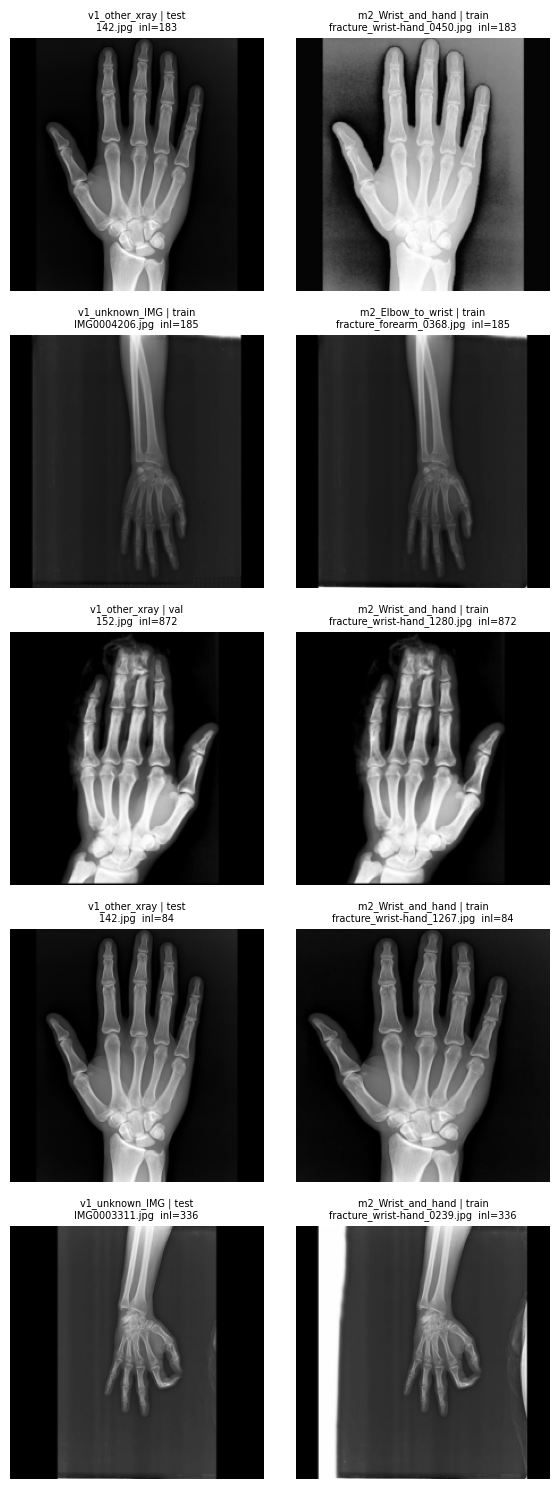

In [14]:
show_cross(50, 100000)

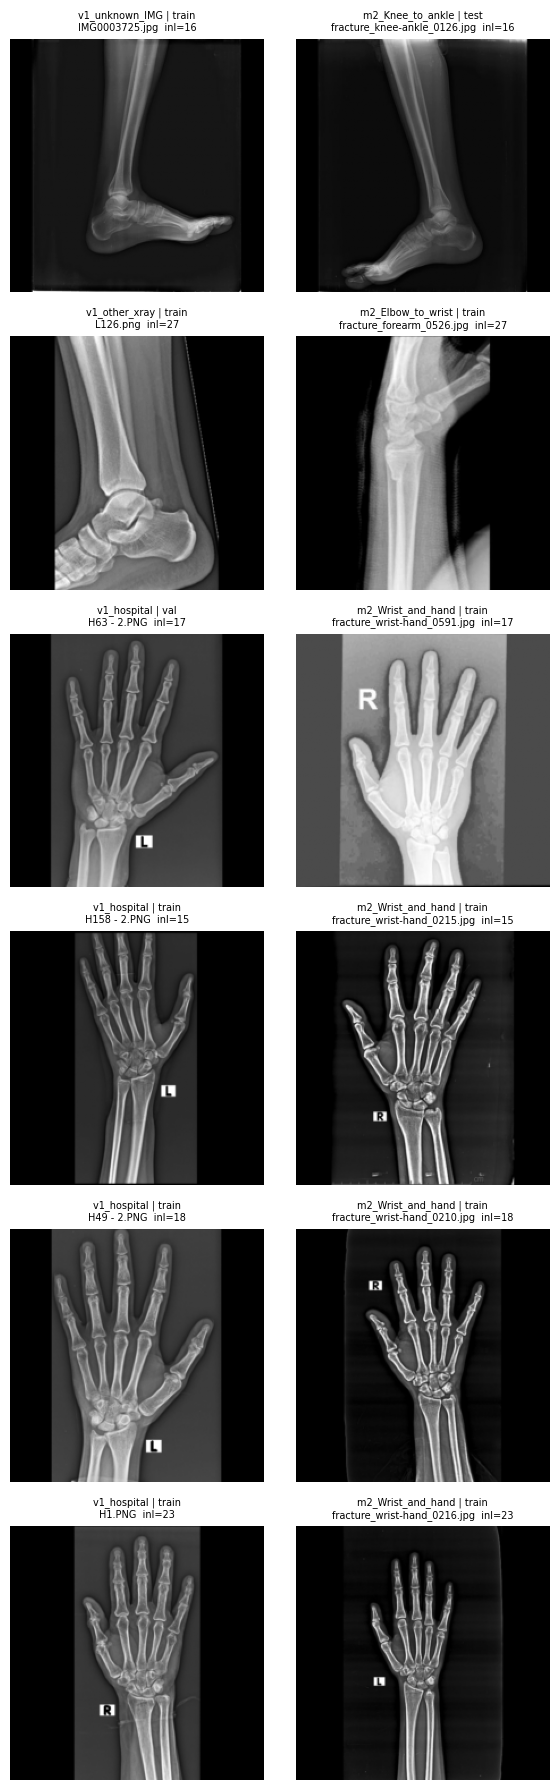

In [15]:
show_cross(15, 49)

### Step 4 findings
≥50 inliers: all inspected pairs = same X-ray (incl. v1 test/val ↔ Model 2 train → leakage).
15–49: mostly different X-rays sharing L/R markers, but at least one true copy at 16 inliers.
Decision (safe side): drop every v1 X-ray with ≥15 inliers to any Model 2 image (Model 2 split is the pipeline reference).

## Step 5 – Final dataset and split
v1 images keep the v1 split, Model 2 images keep the Model 2 split, new negatives get a random 70/15/15 split per source.
Output: manifest_split_v2.csv (cache_idx = row in cache_224_v2.npz).

In [16]:
LEAK_T = 15
leak_v1 = cross.loc[cross.inliers >= LEAK_T, 'i'].astype(int).unique()
inv.loc[leak_v1, ['keep', 'drop_reason']] = [False, 'near_dup_of_model2']
print('v1 X-rays dropped as near-duplicates of Model 2 images:', len(leak_v1))
print(inv.loc[leak_v1].groupby(['source', 'split']).size().to_string())

v1 X-rays dropped as near-duplicates of Model 2 images: 126
source          split
v1_grazpedwri   train     1
v1_hospital     test     13
                train    47
                val      10
v1_knee_kaggle  train     6
v1_other_xray   test      1
                train     7
                val       3
v1_unknown_IMG  test      6
                train    27
                val       5


In [17]:
rng = np.random.default_rng(SEED)
for src, g in inv[inv.source.str.startswith('new_')].groupby('source'):
    idx = rng.permutation(g.index.values); n = len(idx)
    a, b = int(0.70 * n), int(0.85 * n)
    inv.loc[idx[:a], 'split'] = 'train'; inv.loc[idx[a:b], 'split'] = 'val'; inv.loc[idx[b:], 'split'] = 'test'
print(inv[inv.source.str.startswith('new_')].groupby(['source', 'split']).size().unstack().to_string())

split                      test  train  val
source                                     
new_Microscopy_BloodMNIST    45    210   45
new_OCT_OCTMNIST             45    210   45
new_Objects_Imagenette       90    420   90
new_Skin_DermaMNIST          45    210   45


In [18]:
data = inv[inv.keep].copy()
data['cache_idx'] = data.index                       # row number in cache_224_v2.npz
data['y'] = (data.label == 'X_RAY').astype(int)

print(pd.crosstab(data.label, data.split, margins=True)[['train', 'val', 'test', 'All']])
print('\nSplit %:', (data.split.value_counts(normalize=True) * 100).round(1).to_dict())
print('Groups spread over more than one split:', (data.groupby('group').split.nunique() > 1).sum())
print('\nPer source:'); print(pd.crosstab(data.source, data.split)[['train', 'val', 'test']].to_string())

data.to_csv(OUT_DIR / 'manifest_split_v2.csv', index=False)
inv.to_csv(OUT_DIR / 'inventory_v2.csv', index=False)
print('\nSaved:', OUT_DIR / 'manifest_split_v2.csv')

split     train   val  test   All
label                            
NON_XRAY   2327   499   498  3324
X_RAY      3689   759   765  5213
All        6016  1258  1263  8537

Split %: {'train': 70.5, 'test': 14.8, 'val': 14.7}
Groups spread over more than one split: 0

Per source:
split                      train  val  test
source                                     
m2_Elbow_to_wrist            442   82    83
m2_Foot_and_ankle             78   15    12
m2_Hip_to_knee               174   30    35
m2_Knee_to_ankle             208   51    40
m2_OTHER                     345   69    70
m2_Shoulder_to_elbow         360   68    75
m2_Wrist_and_hand           1031  210   204
new_Microscopy_BloodMNIST    210   45    45
new_OCT_OCTMNIST             210   45    45
new_Objects_Imagenette       420   90    90
new_Skin_DermaMNIST          210   45    45
v1_animals_512_unknown       231   42    47
v1_brain_mri_kaggle          206   52    50
v1_ct_organamnist            198   52    50
v1_grazpedwri     